# Hypothesis 1: tutoring attendance and term-3 failure

If referred students attend a higher proportion of scheduled tutoring sessions before term 3, then they will have a lower term-3 failure rate in the tutored subject, comparing similar prior achievement and referral timing.

Run this notebook from the project folder. Existing cleaning and exploration files are not modified. Record the hypothesis revision in the submitted repository before model results. This notebook has not been run against the course server.

## Setup
Select your existing Python notebook kernel. Required packages: numpy, pandas, matplotlib, scikit-learn, mlflow, requests, joblib, ipykernel. If needed, run `%pip install numpy pandas matplotlib scikit-learn mlflow requests joblib ipykernel` yourself in a separate cell and restart the kernel. No installation or environment creation runs automatically.

## Fixed comparison
One row per student and referred subject; at least one scheduled session before February 18, 2026. Zero attendees remain eligible. Failure is any term-3 course below 60 in that subject. Expected courses come from the year-long course enrollments across all terms. Missing outcomes remain unknown. Primary analysis excludes unknown attendance; lower/upper attendance bounds are reported for sensitivity if any exists. Missing GPA uses training-only median imputation plus a missingness indicator.

Model A: prior GPA, referral timing, school, subject. Model B: identical controls plus attendance proportion. Logistic regression, C=1, same preprocessing and student-grouped split. Held fixed: population, outcomes, controls, model settings and partitions. Varied: inclusion of attendance. Choose by mean validation log loss, before opening the final test results. Predictive improvement alone does not establish the hypothesized direction or causation.

Student-grouped 80/20 development/test split and three development folds are generated once and reused. This evaluates new students in the same district/year, not future years or unseen schools. All subjects of a student stay together. Every fit starts inside an MLflow run. The final test is scored once per output directory after selection. Bootstrap uncertainty resamples students, refits Model B, and is exploratory, conditional on the model specification; shared school/tutor dependence and unmeasured referral reasons remain limitations.


In [3]:
from pathlib import Path
import os, json, hashlib, platform, getpass, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss, accuracy_score
import sklearn, mlflow, joblib
ROOT = Path.cwd()
assert (ROOT / 'cleaned').is_dir(), 'Open the notebook from the project folder.'
OUT = ROOT / 'hypothesis1_outputs'
SEED = 4913
CUTOFF = '2026-02-18'
BOOTSTRAPS = 200


## Build and check the analysis population
This section only reads data. Attendance bounds treat every unknown session as absent or present; neither is silently assumed correct. If unknown attendance exists, the primary complete-attendance result must be accompanied by bound-model sensitivity runs before a final verdict.


In [5]:
def read(name):
    return pd.read_csv(ROOT / 'cleaned' / f'{name}.csv', dtype={'student_id': str, 'school_code': str})
students, referrals, sessions, grades, courses = [read(n) for n in
    ['students', 'tutoring_referrals', 'tutoring_sessions', 'term_grades', 'courses']]
keys = ['student_id', 'subject_area']
pre = sessions.loc[sessions.session_date.lt(CUTOFF)].copy()
pre['present'] = pre.attendance.eq('Present').astype(int)
pre['unknown'] = pre.attendance.isna().astype(int)
attendance = pre.groupby(keys).agg(scheduled=('session_id', 'size'),
    attended=('present', 'sum'), unknown_attendance=('unknown', 'sum')).reset_index()
attendance['attendance_lower'] = attendance.attended / attendance.scheduled
attendance['attendance_upper'] = (attendance.attended + attendance.unknown_attendance) / attendance.scheduled
attendance['attendance_proportion'] = attendance.attendance_lower.where(attendance.unknown_attendance.eq(0))
# Expected year-long enrollments also identify entirely absent term-3 grade rows.
enrollments = grades[['student_id', 'course_code']].drop_duplicates()
term3 = grades.loc[grades.term.eq(3), ['student_id', 'course_code', 'grade_percent']]
assert not term3.duplicated(['student_id','course_code']).any()
subject_grades = enrollments.merge(term3, how='left', on=['student_id','course_code'], validate='one_to_one').merge(
    courses[['course_code','subject_area']], on='course_code', validate='many_to_one')
subject_grades['failed_observed'] = subject_grades.grade_percent.lt(60)
outcomes = subject_grades.groupby(keys).agg(expected=('course_code','size'),
    observed=('grade_percent','count'), any_failure=('failed_observed','max')).reset_index()
outcomes['failure'] = outcomes.any_failure.astype(float).where(
    outcomes.any_failure | outcomes.observed.eq(outcomes.expected))
cohort = referrals.merge(attendance, on=keys, how='inner', validate='one_to_one').merge(
    students[['student_id','prior_year_gpa']], on='student_id', validate='many_to_one').merge(
    outcomes[keys+['failure']], on=keys, how='left', validate='one_to_one')
cohort['referral_days'] = (pd.to_datetime(cohort.referral_date) - pd.Timestamp('2025-08-01')).dt.days
assert cohort.referral_date.lt(CUTOFF).all()
assert not cohort.duplicated(keys).any()
audit = pd.DataFrame({'measure': ['all referrals','eligible student-subjects','unknown outcomes',
    'unknown attendance records','missing prior GPA'], 'count': [len(referrals),len(cohort),
    cohort.failure.isna().sum(),cohort.attendance_proportion.isna().sum(),cohort.prior_year_gpa.isna().sum()]})
display(audit)
display(cohort[['scheduled','attendance_lower','attendance_upper','prior_year_gpa']].describe())
data = cohort.dropna(subset=['failure','attendance_proportion']).reset_index(drop=True)
data['failure'] = data.failure.astype(int)
assert data.failure.nunique() == 2


,measure,count
0,all referrals,14917
1,eligible student-subjects,13538
2,unknown outcomes,0
3,unknown attendance records,0
4,missing prior GPA,378


,scheduled,attendance_lower,attendance_upper,prior_year_gpa
count,13538.000000,13538.000000,13538.000000,13160.000000
mean,17.698774,0.567819,0.567819,2.141641
std,4.590698,0.251159,0.251159,0.624252
min,7.000000,0.000000,0.000000,0.000000
25%,16.000000,0.380952,0.380952,1.720000
50%,19.000000,0.588235,0.588235,2.140000
75%,21.000000,0.772727,0.772727,2.560000
max,23.000000,1.000000,1.000000,4.000000


## Course MLflow connection
Run on campus Wi-Fi or another network with access to `http://10.0.100.20:5000`. This is the MLflow address, not the VM portal. Enter your credentials at the prompts; the password is not stored in notebook source or exported artifacts. Environment variables can also supply credentials. Connection failure stops execution instead of silently logging locally.

Connection and authentication follow the [official MLflow documentation](https://mlflow.org/docs/latest/self-hosting/security/basic-http-auth/). A read-only check verifies login; an artifact preflight verifies that this host can also upload and download run files before any fit. If the course server advertises a VM-only artifact path, the instructor must expose an artifact proxy/store reachable from this host.


In [1]:
# This connection cell can run independently of the earlier imports cell.
import os
import getpass
import tempfile
from pathlib import Path
try:
    import mlflow
except ImportError as exc:
    raise ImportError('MLflow is not installed in this notebook kernel. Run %pip install mlflow in a separate cell, then retry.') from exc
ROOT = Path.cwd()

MLFLOW_SERVER = 'http://10.0.100.20:5000'
# Prompt on every run so previously mistyped credentials can be replaced.
username = input('Course MLflow username: ').strip()
password = getpass.getpass('Course MLflow password: ')
if not username or not password:
    raise ValueError('Enter both credentials, then rerun this cell.')
os.environ['MLFLOW_TRACKING_USERNAME'] = username
os.environ['MLFLOW_TRACKING_PASSWORD'] = password
del password
os.environ['MLFLOW_HTTP_REQUEST_TIMEOUT'] = '15'
os.environ['MLFLOW_HTTP_REQUEST_MAX_RETRIES'] = '1'
if os.environ.get('MLFLOW_TRACKING_TOKEN'):
    raise RuntimeError('An existing MLflow token overrides basic authentication; clear it for this course login.')
mlflow.set_tracking_uri(MLFLOW_SERVER)
client = mlflow.tracking.MlflowClient()
try:
    client.search_experiments(max_results=1)
except Exception as exc:
    raise RuntimeError('Cannot authenticate to course MLflow. Check campus access, credentials and server status.') from exc
experiment_name = input('Experiment name (use your instructor-assigned name if provided): ').strip()
if not experiment_name:
    raise ValueError('An experiment name is required.')
experiment = mlflow.set_experiment(experiment_name)
with tempfile.TemporaryDirectory(dir=ROOT) as tmp:
    probe = Path(tmp) / 'connection_check.txt'
    probe.write_text('Hypothesis 1 host artifact connectivity check', encoding='utf-8')
    with mlflow.start_run(run_name='H1_connection_preflight') as run:
        mlflow.set_tag('purpose', 'connection check; no model fitted')
        mlflow.log_artifact(str(probe), artifact_path='preflight')
        fetched = client.download_artifacts(run.info.run_id, 'preflight/connection_check.txt', tmp)
        assert Path(fetched).read_text(encoding='utf-8') == probe.read_text(encoding='utf-8')
print('Authenticated and artifact transfer verified. Ready for tracked experiments.')


🏃 View run H1_connection_preflight at: http://10.0.100.20:5000/#/experiments/117/runs/a54c5738102a410a978a4ea7077871e3
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117
Authenticated and artifact transfer verified. Ready for tracked experiments.


## Freeze shared partitions and provenance
Reruns reuse deterministic assignments and reject changed inputs/settings in the same output folder. Save these files with your submitted results. The split manifest contains district student identifiers; keep it within the authorized course submission.


In [6]:
OUT.mkdir(exist_ok=True)
fingerprints = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in
    [ROOT/'cleaned'/f'{n}.csv' for n in ['students','tutoring_referrals','tutoring_sessions','term_grades','courses']]}
config = dict(seed=SEED, cutoff=CUTOFF, bootstraps=BOOTSTRAPS, C=1.0,
    primary_metric='log_loss', input_sha256=fingerprints,
    versions={n: __import__(n).__version__ for n in ['numpy','pandas','sklearn','mlflow']},
    python=platform.python_version())
config_path = OUT/'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, 'Inputs/settings changed: use a separate output directory.'
else:
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
dev_idx, test_idx = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(data, groups=data.student_id))
dev = data.iloc[dev_idx].reset_index(drop=True)
test = data.iloc[test_idx].reset_index(drop=True)
folds = list(GroupKFold(n_splits=3).split(dev, dev.failure, dev.student_id))
assert set(dev.student_id).isdisjoint(test.student_id)
manifest = data[keys].copy()
manifest['partition'] = 'development'
manifest.loc[test_idx,'partition'] = 'test'
manifest['validation_fold'] = -1
for fold, (tr, va) in enumerate(folds):
    assert set(dev.iloc[tr].student_id).isdisjoint(dev.iloc[va].student_id)
    manifest.loc[dev_idx[va],'validation_fold'] = fold
manifest.to_csv(OUT/'split_manifest.csv',index=False)
audit.to_csv(OUT/'cohort_audit.csv',index=False)
print('Development and test student groups are disjoint. Shared folds frozen.')


Development and test student groups are disjoint. Shared folds frozen.


In [7]:
base_numeric = ['prior_year_gpa','referral_days']
categorical = ['school_code','subject_area']
def make_model(attendance=False):
    numeric = base_numeric + (['attendance_proportion'] if attendance else [])
    prep = ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                             ('scale',StandardScaler())]),numeric),
        ('category',OneHotEncoder(handle_unknown='ignore'),categorical)])
    return Pipeline([('features',prep),('classifier',LogisticRegression(C=1.0,max_iter=3000,random_state=SEED))])
def metrics(model, frame):
    y = frame.failure
    p = model.predict_proba(frame)[:,1]
    return dict(log_loss=log_loss(y,p,labels=[0,1]),
        brier=brier_score_loss(y,p),accuracy=accuracy_score(y,p>=.5),
        **({'roc_auc':roc_auc_score(y,p)} if y.nunique()==2 else {}))
def start_params(name, phase, **extra):
    mlflow.log_params(dict(candidate=name, phase=phase, C=1.0,seed=SEED,
        controls='prior_year_gpa,referral_days,school_code,subject_area',
        attendance=name=='B',missing_gpa='training median plus indicator',**extra))
    mlflow.log_artifact(str(config_path))
    mlflow.log_artifact(str(OUT/'split_manifest.csv'))
    mlflow.log_artifact(str(OUT/'cohort_audit.csv'))
    mlflow.log_artifact(str(ROOT/'hypothesis1_experiments.ipynb'))
    mlflow.log_artifact(str(ROOT/'PROJECT.md'))
results=[]
run_ids=[]
for name in ['A','B']:
    for fold,(tr,va) in enumerate(folds):
        with mlflow.start_run(run_name=f'H1_{name}_fold_{fold}') as run:
            run_ids.append(run.info.run_id)
            start_params(name,'cross_validation',fold=fold)
            model=make_model(name=='B')
            model.fit(dev.iloc[tr],dev.iloc[tr].failure)
            train_scores=metrics(model,dev.iloc[tr])
            valid_scores=metrics(model,dev.iloc[va])
            mlflow.log_metrics({f'train_{k}':v for k,v in train_scores.items()})
            mlflow.log_metrics({f'validation_{k}':v for k,v in valid_scores.items()})
            gap=valid_scores['log_loss']-train_scores['log_loss']
            mlflow.log_metric('log_loss_gap',gap)
            path=OUT/f'model_{name}_fold_{fold}.joblib'
            joblib.dump(model,path)
            mlflow.log_artifact(str(path),artifact_path='model')
            results.append(dict(candidate=name,fold=fold,run_id=run.info.run_id,
                train_log_loss=train_scores['log_loss'],log_loss_gap=gap,**valid_scores))
cv_results=pd.DataFrame(results)
cv_results.to_csv(OUT/'validation_results.csv',index=False)
summary=cv_results.groupby('candidate').log_loss.agg(['mean','std'])
display(cv_results)
display(summary)
chosen=summary['mean'].idxmin()
print('Selected by mean validation log loss:',chosen)


🏃 View run H1_A_fold_0 at: http://10.0.100.20:5000/#/experiments/119/runs/54df00fdeee44e8cb2091f84dd6c6920
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/119
🏃 View run H1_A_fold_1 at: http://10.0.100.20:5000/#/experiments/119/runs/c9be8f08bdc845c08208d02284ea3e37
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/119
🏃 View run H1_A_fold_2 at: http://10.0.100.20:5000/#/experiments/119/runs/3ec26dcef42f41f0a14e187b18aec444
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/119
🏃 View run H1_B_fold_0 at: http://10.0.100.20:5000/#/experiments/119/runs/93ebda10d8124c178cc9fef1d625f521
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/119
🏃 View run H1_B_fold_1 at: http://10.0.100.20:5000/#/experiments/119/runs/d22ce5a062bf4be0afa9f1d8e109f1cd
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/119
🏃 View run H1_B_fold_2 at: http://10.0.100.20:5000/#/experiments/119/runs/bf52668eed3c4119929996fd52d792cd
🧪 View experiment at: http://10.0.100.

,candidate,fold,run_id,train_log_loss,log_loss_gap,log_loss,brier,accuracy,roc_auc
0,A,0,54df00fdeee44e8cb2091f84dd6c6920,0.356608,0.005576,0.362185,0.114814,0.832456,0.845384
1,A,1,c9be8f08bdc845c08208d02284ea3e37,0.354799,0.010823,0.365622,0.114338,0.841828,0.837694
2,A,2,3ec26dcef42f41f0a14e187b18aec444,0.360560,-0.006084,0.354477,0.112449,0.841828,0.846420
3,B,0,93ebda10d8124c178cc9fef1d625f521,0.339218,0.004664,0.343882,0.108020,0.849903,0.862620
4,B,1,d22ce5a062bf4be0afa9f1d8e109f1cd,0.338307,0.007179,0.345485,0.108849,0.849584,0.860551
5,B,2,bf52668eed3c4119929996fd52d792cd,0.341313,-0.001505,0.339808,0.107792,0.849030,0.861300


,mean,std
candidate,,
A,0.360761,0.005708
B,0.343059,0.002927


Selected by mean validation log loss: B


## Attendance association and student bootstrap
Model B is prespecified for the hypothesis even if A predicts better. Report the odds ratio for a 10-percentage-point attendance increase and its student-bootstrap percentile interval. An interval entirely below 1 supports the predicted association; entirely above 1 contradicts it; an interval including 1 leaves the direction unresolved. These are model-based exploratory intervals, not causal effects. Every bootstrap fit is tracked.


🏃 View run H1_B_development_association at: http://10.0.100.20:5000/#/experiments/117/runs/f7f7092383fd4f1795dabe8e67f8b706
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117
🏃 View run H1_B_student_bootstrap_000 at: http://10.0.100.20:5000/#/experiments/117/runs/7a90a534bce34a6c88c52bf891659d93
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117
🏃 View run H1_B_student_bootstrap_001 at: http://10.0.100.20:5000/#/experiments/117/runs/c72af50532ae4071ae1d49cf69570ecd
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117
🏃 View run H1_B_student_bootstrap_002 at: http://10.0.100.20:5000/#/experiments/117/runs/6ac34c8ef63b491f83dd95cc0a4a21e5
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117
🏃 View run H1_B_student_bootstrap_003 at: http://10.0.100.20:5000/#/experiments/117/runs/6d6e4111ecda41f8b95c19fa5e559bc9
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117
🏃 View run H1_B_student_bootstrap_004 at: http://10.0.100.20:5000/#/

,odds_ratio_per_10pp,ci_lower,ci_upper,valid_bootstraps,verdict
0,0.794812,0.775294,0.814691,200,supported


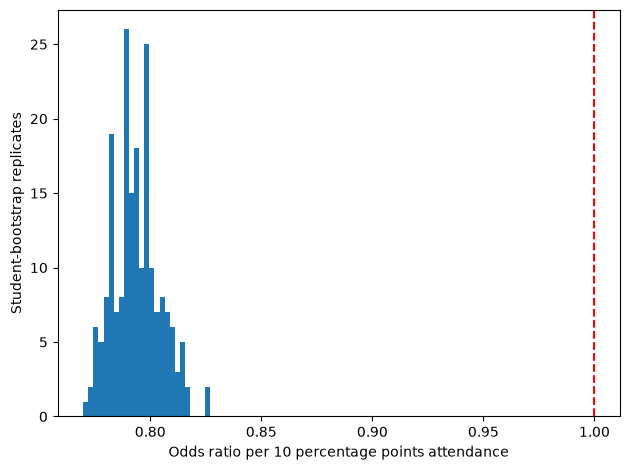

In [6]:
def attendance_or(model):
    features=model.named_steps['features']
    names=features.get_feature_names_out().tolist()
    j=names.index('numeric__attendance_proportion')
    scaler=features.named_transformers_['numeric'].named_steps['scale']
    beta=model.named_steps['classifier'].coef_[0,j]/scaler.scale_[2]
    return float(np.exp(beta*.1))
with mlflow.start_run(run_name='H1_B_development_association') as run:
    run_ids.append(run.info.run_id)
    start_params('B','association')
    association_model=make_model(True).fit(dev,dev.failure)
    estimate=attendance_or(association_model)
    mlflow.log_metric('odds_ratio_per_10pp',estimate)
    path=OUT/'association_model.joblib'
    joblib.dump(association_model,path)
    mlflow.log_artifact(str(path))
rng=np.random.default_rng(SEED)
groups={sid:g for sid,g in dev.groupby('student_id',sort=False)}
ids=list(groups)
bootstrap=[]
for b in range(BOOTSTRAPS):
    sampled=rng.choice(ids,size=len(ids),replace=True)
    frame=pd.concat([groups[sid] for sid in sampled],ignore_index=True)
    with mlflow.start_run(run_name=f'H1_B_student_bootstrap_{b:03d}') as run:
        run_ids.append(run.info.run_id)
        start_params('B','student_bootstrap',replicate=b)
        if frame.failure.nunique()<2:
            mlflow.set_tag('status_reason','single outcome class; skipped')
            continue
        fitted=make_model(True).fit(frame,frame.failure)
        value=attendance_or(fitted)
        mlflow.log_metric('odds_ratio_per_10pp',value)
        bootstrap.append(value)
if len(bootstrap)<.95*BOOTSTRAPS:
    raise RuntimeError('Too many invalid bootstrap replicates for a verdict.')
lo,hi=np.quantile(bootstrap,[.025,.975])
verdict='supported' if hi<1 else ('rejected' if lo>1 else 'unresolved')
if cohort.unknown_attendance.gt(0).any():
    verdict='unresolved: unknown-attendance sensitivity fits are required'
association=pd.DataFrame([dict(odds_ratio_per_10pp=estimate,ci_lower=lo,ci_upper=hi,
    valid_bootstraps=len(bootstrap),verdict=verdict)])
association.to_csv(OUT/'hypothesis_verdict.csv',index=False)
display(association)
plt.hist(bootstrap,bins=25)
plt.axvline(1,color='red',linestyle='--')
plt.xlabel('Odds ratio per 10 percentage points attendance')
plt.ylabel('Student-bootstrap replicates')
plt.tight_layout()
plt.savefig(OUT/'attendance_association.png')
plt.show()


## Final test: once after selection
Run after the model is selected above. A persisted result blocks accidental rescoring in this output directory. No other candidate is scored on the test set. An interrupted run after creating the marker requires inspection of its MLflow run, rather than blindly rerunning.


In [7]:
test_marker=OUT/'final_test_started.json'
if test_marker.exists():
    raise RuntimeError('Final test already started/scored. Review the existing MLflow run and saved results; do not rescore.')
with mlflow.start_run(run_name=f'H1_{chosen}_final_test') as run:
    run_ids.append(run.info.run_id)
    start_params(chosen,'final_test')
    final_model=make_model(chosen=='B').fit(dev,dev.failure)
    test_marker.write_text(json.dumps(dict(run_id=run.info.run_id,candidate=chosen)),encoding='utf-8')
    scores=metrics(final_model,test)
    mlflow.log_metrics({f'test_{k}':v for k,v in scores.items()})
    final_table=pd.DataFrame([dict(candidate=chosen,run_id=run.info.run_id,**scores)])
    final_table.to_csv(OUT/'final_test_results.csv',index=False)
    model_path=OUT/'final_model.joblib'
    joblib.dump(final_model,model_path)
    for path in [model_path,OUT/'final_test_results.csv',OUT/'validation_results.csv',
                 OUT/'hypothesis_verdict.csv',OUT/'attendance_association.png']:
        mlflow.log_artifact(str(path))
display(final_table)


🏃 View run H1_B_final_test at: http://10.0.100.20:5000/#/experiments/117/runs/0c6cd75236f2411c83b5d53b76a90cec
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/117


,candidate,run_id,log_loss,brier,accuracy,roc_auc
0,B,0c6cd75236f2411c83b5d53b76a90cec,0.326004,0.102716,0.854821,0.875528


## Export the course run table
Exports parameters, metrics, run IDs and names from this experiment. Save the table and numerical results in the course repository. Run this export separately if a previous fit failed so failed runs are included too. Do not export credentials or raw attendance/grade data to MLflow.


In [4]:
runs=mlflow.search_runs(experiment_ids=[experiment.experiment_id],output_format='pandas',max_results=50000)
columns=[c for c in runs.columns if c in ['run_id','status','start_time','end_time','tags.mlflow.runName']
         or c.startswith(('params.','metrics.'))]
runs[columns].to_csv(OUT/'mlflow_run_table.csv',index=False)
print('Saved run table and results to',OUT)
display(runs[columns])


Saved run table and results to c:\Users\jlvr0\OneDrive\Documents\Data Cleaning\hypothesis1_outputs


,run_id,status,start_time,end_time,metrics.test_accuracy,metrics.test_log_loss,metrics.test_roc_auc,metrics.test_brier,metrics.odds_ratio_per_10pp,metrics.train_brier,...,params.attendance,params.C,params.missing_gpa,params.phase,params.controls,params.candidate,params.seed,params.replicate,params.fold,tags.mlflow.runName
0,a54c5738102a410a978a4ea7077871e3,FINISHED,2026-11-11 16:00:13.157+00:00,2026-11-11 16:00:17.448+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,H1_connection_preflight
1,0c6cd75236f2411c83b5d53b76a90cec,FINISHED,2026-11-10 02:44:32.822+00:00,2026-11-10 02:44:36.394+00:00,0.854821,0.326004,0.875528,0.102716,NaN,NaN,...,True,1.0,training median plus indicator,final_test,"prior_year_gpa,referral_days,school_code,subje...",B,4913,NaN,NaN,H1_B_final_test
2,5237df6c330c4b138f06118734d89eaf,FINISHED,2026-11-10 02:43:59.301+00:00,2026-11-10 02:44:02.116+00:00,NaN,NaN,NaN,NaN,0.797049,NaN,...,True,1.0,training median plus indicator,student_bootstrap,"prior_year_gpa,referral_days,school_code,subje...",B,4913,199,NaN,H1_B_student_bootstrap_199
3,51c45ade88e144c383c9bbe740dc5726,FINISHED,2026-11-10 02:43:54.146+00:00,2026-11-10 02:43:57.032+00:00,NaN,NaN,NaN,NaN,0.799004,NaN,...,True,1.0,training median plus indicator,student_bootstrap,"prior_year_gpa,referral_days,school_code,subje...",B,4913,198,NaN,H1_B_student_bootstrap_198
4,a8ee0a6db71945b490d741f33d0a676e,FINISHED,2026-11-10 02:43:49.712+00:00,2026-11-10 02:43:52.591+00:00,NaN,NaN,NaN,NaN,0.801870,NaN,...,True,1.0,training median plus indicator,student_bootstrap,"prior_year_gpa,referral_days,school_code,subje...",B,4913,197,NaN,H1_B_student_bootstrap_197
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
205,60701a52888c4179a9950c66e2220e44,FINISHED,2026-11-10 02:26:13.034+00:00,2026-11-10 02:26:16.987+00:00,NaN,NaN,NaN,NaN,NaN,0.107375,...,True,1.0,training median plus indicator,cross_validation,"prior_year_gpa,referral_days,school_code,subje...",B,4913,NaN,0,H1_B_fold_0
206,97d8d99fb0d24a9797cf519eb4e4af25,FINISHED,2026-11-10 02:26:07.961+00:00,2026-11-10 02:26:11.943+00:00,NaN,NaN,NaN,NaN,NaN,0.113619,...,False,1.0,training median plus indicator,cross_validation,"prior_year_gpa,referral_days,school_code,subje...",A,4913,NaN,2,H1_A_fold_2
207,8b13e23f28ec47dd87dbb0a07ea3e49b,FINISHED,2026-11-10 02:26:02.963+00:00,2026-11-10 02:26:06.841+00:00,NaN,NaN,NaN,NaN,NaN,0.112555,...,False,1.0,training median plus indicator,cross_validation,"prior_year_gpa,referral_days,school_code,subje...",A,4913,NaN,1,H1_A_fold_1
208,9b409e573c3d4f52bb972036bde1b516,FINISHED,2026-11-10 02:25:57.745+00:00,2026-11-10 02:26:01.780+00:00,NaN,NaN,NaN,NaN,NaN,0.112410,...,False,1.0,training median plus indicator,cross_validation,"prior_year_gpa,referral_days,school_code,subje...",A,4913,NaN,0,H1_A_fold_0


## Interpretation to include in the submission
Report the cohort counts, missingness, attendance odds ratio with interval, verdict, validation mean/spread and train-validation gaps, selected candidate, and its once-only test scores. Explain whether adding attendance improved prediction separately from whether its association was negative. Flat/uncertain estimates do not support the predicted direction; positive estimates contradict it. Prior GPA and referral timing do not eliminate unmeasured selection, motivation, private help, or school/tutor clustering. Attendance during term 3 is not modeled. These results cannot establish that tutoring caused passing or justify funding cuts by themselves.
